# Fine-Tuning Genomic LLMs

---

## Learning Outcomes

By the end of this session, participants will be able to:
- fine-tune a pretrained genomic transformer with the Hugging Face `Trainer` API
- set up `TrainingArguments`, including early stopping and checkpointing
- save, reload, and run inference with a fine-tuned model
- evaluate a fine-tuned sequence classifier

## credits

This notebook is adapted from [Meg Hedge's ECCB2026 tutorial](https://github.com/meghegde/genomic-llms-in-practice/tree/main).

In this notebook, we take a pretrained DNA language model and adapt it to a downstream classification task — promoter vs. non-promoter — instead of using it off-the-shelf as we did with ESM-2 in the previous session. We rely on the Hugging Face `Trainer` API to handle the training loop, and we finish with *in silico* saturated mutagenesis to interrogate what the model has learned.

We use [DNABERT (6-mer)](https://huggingface.co/zhihan1996/DNA_bert_6), which tokenizes DNA into overlapping 6-mers (as in the first session) and was pretrained with masked-token prediction (as in the second). Unlike the previous notebooks, this session requires a GPU (a T4 on Colab or Kaggle is enough).


## Install and import required packages

In [ ]:
# Installing required libraries
!pip -q install transformers datasets evaluate accelerate scikit-learn seaborn matplotlib


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 4.9 MB/s eta 0:00:00


In [ ]:
# Importing required libraries
import numpy as np
import pandas as pd
import torch

from datasets import load_dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    EarlyStoppingCallback
)

from sklearn.metrics import accuracy_score, f1_score


## Why fine-tune?

In the previous sessions we used pretrained models **off-the-shelf**. Fine-tuning goes one step further: we keep everything the model learned during pre-training and adapt it to a specific task using a small labelled dataset — transfer learning.

![](../images/dallatorre2023_fig1.png)

Figure 1 c. & d. from [Dalla-Torre et al.](https://www.biorxiv.org/content/10.1101/2023.01.11.523679v2)

What we have done in notebook 02 correspond to the top sub-figure, where we keep the LLM unchanged and train a classifier on its embedding.

What we are going to do in this notebook corresponds to the bottom part, where we adjust the weights of the whole model to make them more suitable to our purpose.


---

For genomic sequence classification this typically beats the two obvious alternatives:

- **Classical ML** (random forests or SVMs on handcrafted features, e.g. GC-content or k-mer counts) discards the spatial arrangement of the sequence.
- **Training from scratch** requires far more labelled data and compute than any downstream task can provide.

Because attention (nb02) already encodes the regulatory context of each 6-mer (tokenized as in nb01), fine-tuning mostly redirects this knowledge through a small classification head.



## The Model: DNABERT (6-mer)

We fine-tune [`zhihan1996/DNA_bert_6`](https://huggingface.co/zhihan1996/DNA_bert_6), the 6-mer checkpoint of **DNABERT** ([Ji et al., 2021](https://doi.org/10.1093/bioinformatics/btab083); [code](https://github.com/jerryji1993/DNABERT); [huggingface](huggingface.co/zhihan1996/DNA_bert_6)):

- **Architecture**: a BERT-base-sized bidirectional Transformer — 12 layers, 12 attention heads, hidden size 768 (~90M parameters). The same masked-token pre-training recipe we used with ESM-2 in notebook 02, applied to DNA.
- **Pre-training corpus**: the human genome (GRCh38) — no task labels involved, only masked 6-mer prediction
- **Vocabulary**: the 4^6 = 4,096 possible 6-mers plus 5 special tokens (vocab size 4,101); the sliding-window tokenization below yields ~1 token per nucleotide position
- **Context size**: 512 k-mer tokens ~ 510 bp of DNA — comfortably covers our fixed 300 bp sequences (which is why the benchmark sequences are fixed-length)
- for classification, the masked-LM head is replaced by a small 2-class head (`num_labels=2`), and fine-tuning then updates every weight in the network — exactly the regime depicted above

The original paper already shows where this is going: this model family reached state-of-the-art promoter prediction "after easy fine-tuning using small task-specific labeled data".

In [ ]:
MODEL_NAME = "zhihan1996/DNA_bert_6"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

config.json:   0%|          | 0.00/1.45k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/40.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/28.7k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

## The Task: Promoter Classification

Promoters are short regulatory regions at the start of genes: they tell the transcription machinery where to bind and from which nucleotide to begin reading the gene. Predicting them from sequence alone is a classic binary classification problem — given a window of DNA, is it a promoter or genomic background?

### Dataset

We use the `NT_promoter_all` configuration of the Genomic Benchmarks collection on Hugging Face: [datasets/darlednik/geneb-tasks](https://huggingface.co/datasets/darlednik/geneb-tasks)

- **300 bp human DNA windows**, centered on annotated transcription start sites for positives versus random genomic background for negatives
- **53,276 train / 5,920 test** sequences; label `1` = promoter, `0` = non-promoter
- from the Nucleotide Transformer benchmark suite ([Dalla-Torre et al., 2023](https://www.biorxiv.org/content/10.1101/2023.01.11.523679v2)) — the same paper as the figure above
- the repository aggregates ~100 benchmark configs (`NT_*`, `GB_*`, `GUE_*`, ...): splice sites, enhancers, histone marks, ... — a ready-made playground if you want to fine-tune on a second task

In [ ]:
# Loading dataset
promoter_dataset = load_dataset("darlednik/geneb-tasks", "NT_promoter_all")
promoter_dataset

promoter_dataset["train"][0]

README.md:   0%|          | 0.00/24.3k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/100 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/100 [00:00<?, ?it/s]

tasks/InstaDeepAI_nucleotide_transformer(…): reconstructing file:   0%|          |  0.00B / 16.2MB            

tasks/InstaDeepAI_nucleotide_transformer(…): downloading bytes:           |  0.00B            

test.csv:   0%|          | 0.00/1.80M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/53276 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5920 [00:00<?, ? examples/s]

{'text': 'ATAAAGCAACAGGAGGACACCGGCTCTCGCGTCATTAGGTCACACAATGTCTCAGTTTAAGGCGGGTGGGGTGGGCCAGACTCACAGCTGAGATAGAATTATTGCGAGATAACTCTGTTTAAGTAGCTAGGCTTGAAAATGGACGGTGAGTACCCTAGGACGTGCCCCAGGGCCAGTGGGATAAAGGTACACGCCGGCGGGGGCATGAGTCAGGGGTTTGCGAGCGAAAAAAGGAGCATTGGTTGCTACTGCGTTAGTGGGAACGTAGCTGGTCGCAGAGGGCACCTAATGCTGGCACCC',
 'label': 0}

## Tokenization

### Inside the Genomic Tokenizer

DNABERT_6 represents the DNA sequences using an **overlapping sliding window** of 6-mers (k-mers of length 6).

Why? Because biological signals don't have spaces or punctuation. Overlapping k-mers preserve the continuous spatial context of the sequence, ensuring no biological motif is accidentally split across a token boundary.

A 300 bp sequence therefore yields 295 overlapping 6-mers: we set `max_length=300` below so the full window fits inside the model's 512-position context with no truncation.


In [ ]:
# Visualize the Sliding Window K-mer Extraction
def visualize_kmer_tokenization(sequence, k=6):
    print(f"Raw Sequence: {sequence}\n")
    print(f"Extracted {k}-mers (Sliding Window):")

    kmers = [sequence[i:i+k] for i in range(len(sequence) - k + 1)]
    for i, kmer in enumerate(kmers):
        # Indent to show the overlap visually
        print(f"{' ' * i}{kmer}")

# Testing on a short 15-base sequence
sample_dna = "ATGCGTAACGTTGAC"
visualize_kmer_tokenization(sample_dna)


Raw Sequence: ATGCGTAACGTTGAC

Extracted 6-mers (Sliding Window):
ATGCGT
 TGCGTA
  GCGTAA
   CGTAAC
    GTAACG
     TAACGT
      AACGTT
       ACGTTG
        CGTTGA
         GTTGAC


In [ ]:
# Function to generate overlapping k-mers from a given sequence
def seq2kmer(seq, k=6):
    return " ".join([seq[i:i+k] for i in range(len(seq) - k + 1)])

# Function to tokenize a given sequence
def tokenize_promoter(example):
    # Convert a batch of raw strings to spaced k-mers
    kmer_texts = [seq2kmer(seq) for seq in example["text"]]

    return tokenizer(
        kmer_texts,
        truncation=True,
        padding="max_length",
        max_length=300
    )


tokenized_promoter = promoter_dataset.map(tokenize_promoter, batched=True)


Map:   0%|          | 0/53276 [00:00<?, ? examples/s]

Map:   0%|          | 0/5920 [00:00<?, ? examples/s]

In [ ]:
# Train/Test dataset with 80-20 split
train_promoter = tokenized_promoter["train"].shuffle(seed=42).select(range(20000))
test_promoter = tokenized_promoter["test"].shuffle(seed=42).select(range(2000))
promoter_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2
)


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  359MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: zhihan1996/DNA_bert_6
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


## Determining batch size - GPU memory

Batch size is not a free choice - it is capped by GPU memory. Peak memory during full fine-tuning has two parts:

- **Static cost** (independent of batch size): fp32 training spends ~16 bytes per parameter ( weights (4) + gradients (4) + the two AdamW states (2 × 4) ). For ~90M parameters that is ~1.4 GB, plus ~0.5 GB for the CUDA context and cuDNN kernels. This bill is identical for a batch of 1 or 64.
- **Dynamic cost** (saved activations, needed for backpropagation): it grows *linearly with the batch size*, and with *sequence length* it grows superlinearly — the attention term scales as `batch × heads × s²`. This is what forced the batch to be halved when we widened the window: 128 → 300 tokens multiplies the per-sequence cost roughly 3x (64 → 32).

Rather than trusting a hand-derived formula, **probe and extrapolate**: peak memory as a function of batch size `b` is a straight line,

```
peak(b) = static + slope × b        →   safe_max_batch ≈ 0.8 × (GPU_total − static) / slope
```

so two measurements are enough to fit it; the ~20% margin absorbs allocator fragmentation. The cell below fits the line on your machine's GPU — it costs two mini training steps and returns the model to the CPU afterwards:

In [ ]:
# Empirical batch-size probe: peak memory (fwd + bwd + one AdamW step) at two batch sizes
def probe_batch_memory(model, batch_size, seq_len=300, vocab_size=4101):
    model.train()
    optimizer = torch.optim.AdamW(model.parameters(), lr=2e-5)
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()

    input_ids = torch.randint(5, vocab_size, (batch_size, seq_len), device="cuda")
    attention_mask = torch.ones_like(input_ids)
    labels = torch.randint(0, 2, (batch_size,), device="cuda")

    output = model(input_ids=input_ids, attention_mask=attention_mask, labels=labels)
    output.loss.backward()
    optimizer.step()
    peak_gb = torch.cuda.max_memory_allocated() / 1e9

    del optimizer, output, input_ids, attention_mask, labels
    torch.cuda.empty_cache()
    return peak_gb

if torch.cuda.is_available():
    b1, b2 = 4, 16
    m1 = probe_batch_memory(promoter_model.cuda(), b1)
    m2 = probe_batch_memory(promoter_model, b2)
    promoter_model.cpu()

    slope = (m2 - m1) / (b2 - b1)      # GB added by each extra sequence in the batch
    static = m1 - slope * b1           # weights + gradients + AdamW states + CUDA context
    gpu_total = torch.cuda.get_device_properties(0).total_memory / 1e9
    max_batch = int(0.8 * (gpu_total - static) / slope)

    print(f"GPU total:   {gpu_total:.1f} GB")
    print(f"Static cost: {static:.2f} GB")
    print(f"Per sample:  {slope:.3f} GB (at 300 tokens per sequence)")
    print(f"Safe max batch (80% budget): {max_batch}")
else:
    print("No GPU detected — the probe needs CUDA.")
    print("Expect on a 16 GB GPU: static ~2-2.5 GB, ~0.1-0.2 GB per sample at 300 tokens,")
    print("i.e. a safe batch of roughly 32-64 for this 90M-parameter model.")

## Evaluation Metrics

We use:
- Accuracy
- Weighted F1-score

F1-score is especially important in genomics due to:
- **imbalance**: categories of interest are often massively under-represented
- **asymmetric biological consequences**: we generally consider that False Positives are not equivalent to False Negatives (ie, they have different biological meaning and consequences)
- **sensitivity/precision requirements**: despite imbalance we want to control FDR (precision) while being as sensitive as possible.


In [ ]:
# Function to compute evaluation metrics
def compute_metrics(eval_pred):

    logits, labels = eval_pred

    predictions = np.argmax(logits, axis=-1)

    accuracy = accuracy_score(labels, predictions)

    f1 = f1_score(labels, predictions, average="weighted")

    return {
        "accuracy": accuracy,
        "f1": f1
    }


## TrainingArguments Deep Dive

`TrainingArguments` configures the training loop executed by the `Trainer`. Every argument used in the next cell:

- `output_dir` — folder where checkpoints, logs and configs are written
- `eval_strategy="epoch"` / `save_strategy="epoch"` — evaluate on the test split and save a checkpoint at the end of each epoch; identical strategies are required for the best-model tracking below
- `learning_rate=2e-5` — the golden rule of fine-tuning: 10-100x lower than pre-training rates (the classic BERT band is 1e-5 to 5e-5). Large enough to adapt the features, small enough not to erase the pre-trained knowledge (catastrophic forgetting)
- `per_device_train_batch_size=32` — 64 was safe at 128 tokens per sequence; with the full 300 bp sequences the memory cost roughly triples, so we halve it to stay inside a 16 GB GPU (derived just below). Larger batches finish each epoch faster, with less frequent updates
- `num_train_epochs=1` — the weights are already pre-trained: one pass over the 20k training sequences is enough to reshape the head and the features
- `weight_decay=0.01` — AdamW's decoupled L2 regularization: penalizes large weights to limit overfitting
- `logging_steps=10` — log the training loss every 10 steps so we can watch it decrease

**Model selection.** The *last* checkpoint of a fine-tuning run is not necessarily the best — validation scores typically peak, then decay as the model starts to overfit:

- `load_best_model_at_end=True` + `metric_for_best_model="f1"` — reload the checkpoint with the best validation F1 at the end of training
- `EarlyStoppingCallback(early_stopping_patience=1)` — stop training when validation F1 stops improving for one epoch. This is a `Trainer` **callback**, not a `TrainingArguments` setting

Both monitor the validation metric — the safety net against overfitting that raw training loss cannot provide.

In [ ]:
promoter_training_args = TrainingArguments(
    output_dir="./promoter_results",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=32,
    num_train_epochs=1,
    weight_decay=0.01,
    logging_steps=10,
    load_best_model_at_end=True,
    metric_for_best_model="f1"
)

promoter_trainer = Trainer(
    model=promoter_model,
    args=promoter_training_args,
    train_dataset=train_promoter,
    eval_dataset=test_promoter,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=1)]
)

## Fine-Tuning the Model

Observe:
- training loss
- evaluation metrics
- checkpoint saving
- runtime behavior

In [ ]:
promoter_trainer.train()

promoter_results = promoter_trainer.evaluate()
promoter_results

Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.341849,0.333707,0.855500,0.855393


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Accuracy,F1
0.341849,0.333707,1,0.855500,0.855393


{'eval_loss': 0.3337066173553467,
 'eval_accuracy': 0.8555,
 'eval_f1': 0.8553929276324432}

## Saving and Reloading the Model

Critical for:
- reproducibility
- downstream inference
- sharing checkpoints


In [ ]:
# Saving the fine-tuned model
promoter_trainer.save_model("./promoter_model")
tokenizer.save_pretrained("./promoter_model")

# Loading the saved model back
loaded_promoter_model = AutoModelForSequenceClassification.from_pretrained(
    "./promoter_model"
)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

## Inference
We now perform prediction on unseen sequences.


In [ ]:
# Method to perform prediction on a sequence using the fine-tuned model
def promoter_predict(sequence):

    inputs = tokenizer(
        sequence,
        return_tensors="pt",
        truncation=True,
        padding=True,
        max_length=128
    )

    with torch.no_grad():
        outputs = loaded_promoter_model(**inputs)

    prediction = torch.argmax(outputs.logits, dim=1).item()
    return prediction


In [ ]:
# Run prediction
sample_sequence = promoter_dataset["test"][4000]["text"]

prediction = promoter_predict(sample_sequence)

print("Predicted label:", prediction)
print("Actual label:", promoter_dataset["test"][4000]["label"])


Predicted label: 1
Actual label: 1


## In Silico Saturated Mutagenesis

In the wet lab, researchers perform knockout experiments or saturated mutagenesis to determine which specific nucleotides are essential for a biological function.

We can recreate this digitally. By systematically mutating every position in a sequence window and plotting the drop in the model's confidence, we can force the model to reveal the sequence motifs it considers most critical.


Analyzing Sequence Index 5 (True Label: 1)
Initial Model Confidence: 0.9960


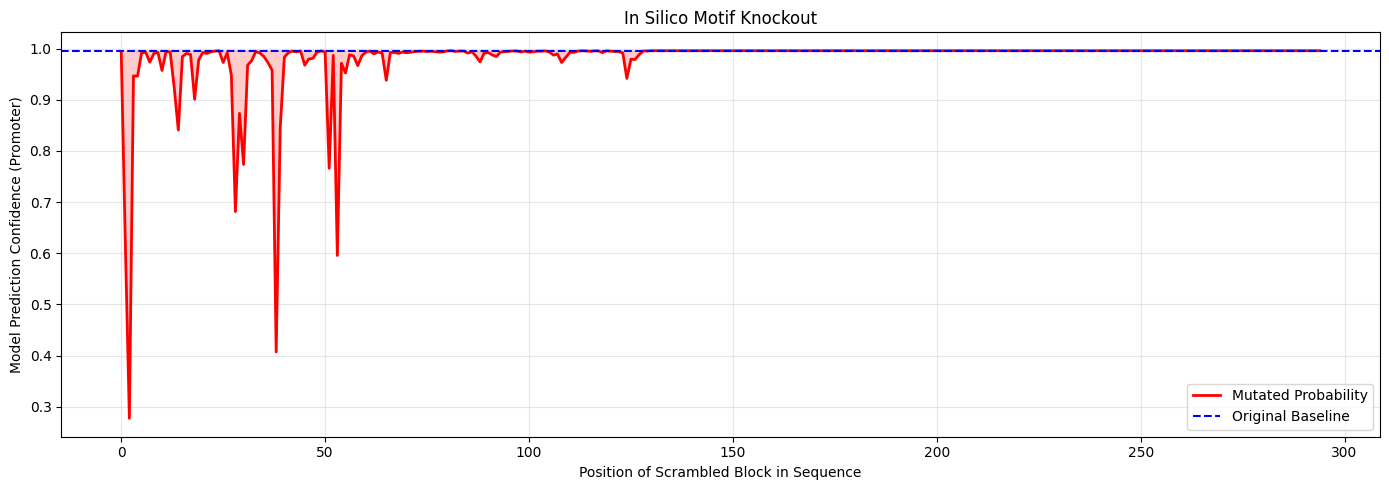

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import torch.nn.functional as F

# Helper functions (included here so the cell is self-contained)
def seq2kmer(seq, k=6):
    return " ".join([seq[i:i+k] for i in range(len(seq) - k + 1)])

def get_promoter_probability(seq):
    kmer_seq = seq2kmer(seq)
    inputs = tokenizer(kmer_seq, return_tensors="pt", truncation=True, max_length=128)
    with torch.no_grad():
        device = loaded_promoter_model.device
        inputs = {k: v.to(device) for k, v in inputs.items()}
        logits = loaded_promoter_model(**inputs).logits
    probs = F.softmax(logits, dim=-1)
    return probs[0][1].item()

SEQ_INDEX = 5
original_sequence = promoter_dataset["test"][SEQ_INDEX]["text"]
true_label = promoter_dataset["test"][SEQ_INDEX]["label"]

print(f"Analyzing Sequence Index {SEQ_INDEX} (True Label: {true_label})")
initial_confidence = get_promoter_probability(original_sequence)
print(f"Initial Model Confidence: {initial_confidence:.4f}")

# 2. In Silico Block Knockout (Sliding 5-bp disruptive window)
window_size = 5
probabilities = []
positions = list(range(len(original_sequence) - window_size))

# Helper to aggressively scramble a DNA block (Swap A<->C, T<->G)
def scramble_block(block):
    mapping = {'A': 'C', 'C': 'A', 'T': 'G', 'G': 'T'}
    return "".join([mapping.get(base, base) for base in block])

for pos in positions:
    # Extract the block and scramble it
    target_block = original_sequence[pos : pos + window_size]
    scrambled_block = scramble_block(target_block)

    # Reconstructing the mutated sequence
    mutated_seq = original_sequence[:pos] + scrambled_block + original_sequence[pos + window_size:]

    # Measure the new probability
    probabilities.append(get_promoter_probability(mutated_seq))

# Plotting the Knockout Sensitivity
plt.figure(figsize=(14, 5))
plt.plot(positions, probabilities, label="Mutated Probability", color="red", linewidth=2)
plt.axhline(y=initial_confidence, color='blue', linestyle='--', label="Original Baseline")

plt.fill_between(positions, probabilities, initial_confidence,
                 where=(np.array(probabilities) < initial_confidence),
                 color='red', alpha=0.2)

plt.title(f"In Silico Motif Knockout")
plt.xlabel("Position of Scrambled Block in Sequence")
plt.ylabel("Model Prediction Confidence (Promoter)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()